# Glacier mapping with GlaViTU (clean, working pipeline)

Repo: [konstantin-a-maslov/scalable_glacier_mapping](https://github.com/konstantin-a-maslov/scalable_glacier_mapping)

**Pipeline:** 3 GeoTIFFs (optical, elevation, slope) → `compile_features.py` → features `.pickle` → GlaViTU inference → `outlines.tif` + `confidence.tif` → polygons (`.shp` / `.geojson`) → plot.

**Needed before running (not in the repo):**
- the pretrained weights, e.g. `weights/glavitu_global_weights.h5` (download link is in the repo README under *Pretrained models*)
- your three GeoTIFFs in `demo_tiff_files/` : `optical.tiff` (6 bands), `elevation.tiff`, `slope.tiff`, all on the same grid

Run top to bottom. Runtime → GPU recommended.

## 1. Get the code and install packages

In [1]:
!git clone -q https://github.com/konstantin-a-maslov/scalable_glacier_mapping.git
%cd scalable_glacier_mapping

/content/scalable_glacier_mapping


In [2]:
!pip -q install uv
!uv venv --python 3.10 /content/venv310
!uv pip install --python /content/venv310/bin/python -q "tensorflow[and-cuda]==2.15.1" "numpy<2" h5py scikit-learn rasterio geopandas opencv-python-headless tqdm scipy matplotlib
!/content/venv310/bin/python -c "import tensorflow as tf, keras; print(tf.__version__, keras.__version__, tf.config.list_physical_devices('GPU'))"

Using CPython 3.10.22
Creating virtual environment at: /content/venv310
Activate with: source /content/venv310/bin/activate
2026-11-10 18:03:27.017515: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-10 18:03:27.017590: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-10 18:03:27.019010: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-10 18:03:27.027946: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA

In [3]:
!nvidia-smi --query-gpu=name,compute_cap,memory.total,driver_version --format=csv

name, compute_cap, memory.total [MiB], driver_version
Tesla T4, 7.5, 15360 MiB, 580.82.07


In [10]:
!nvidia-smi --query-gpu=name,compute_cap,memory.total,driver_version --format=csv

name, compute_cap, memory.total [MiB], driver_version
Tesla T4, 7.5, 15360 MiB, 580.82.07


In [4]:
!/content/venv310/bin/python -c "import tensorflow as tf; print(tf.config.list_physical_devices('GPU')); x=tf.random.normal((1,384,384,6)); y=tf.nn.conv2d(x,tf.random.normal((3,3,6,64)),1,'SAME'); print('conv ok', y.shape, y.device)"

2026-11-10 18:05:45.618628: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-10 18:05:45.618701: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-10 18:05:45.620113: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-10 18:05:45.628089: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-10 18:05:46.740770: W tensorflow/comp

In [11]:
!/content/venv310/bin/python -c "import tensorflow as tf; print(tf.config.list_physical_devices('GPU')); x=tf.random.normal((1,384,384,6)); y=tf.nn.conv2d(x,tf.random.normal((3,3,6,64)),1,'SAME'); print('conv ok', y.shape, y.device)"

2026-11-10 18:10:10.229384: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-10 18:10:10.229456: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-10 18:10:10.230837: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-10 18:10:11.321321: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
2026-11-10 18:10:12.756693: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment vari

In [5]:
import tensorflow as tf
print(tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Check inputs
This fails early with a clear message if the weights or GeoTIFFs are missing.
Upload them via the Colab Files panel (or mount Google Drive and copy them in).

In [6]:
import os

WEIGHTS = "weights/glavitu_global_weights.h5"   # alternatives: glavitu_regional_AWA_weights.h5, glavitu_finetuning_AWA_weights.h5
OPTICAL, ELEVATION, SLOPE = (
    "demo_tiff_files/optical.tif",
    "demo_tiff_files/elevation.tif",
    "demo_tiff_files/slope.tif",
)

os.makedirs("weights", exist_ok=True)
os.makedirs("demo_tiff_files", exist_ok=True)

missing = [p for p in (WEIGHTS, OPTICAL, ELEVATION, SLOPE) if not os.path.exists(p)]
if missing:
    raise FileNotFoundError("Missing: " + ", ".join(missing) +
                            "\nUpload them (Files panel on the left) and re-run this cell.")
print("All inputs found.")

All inputs found.


## 3. Compile features
`compile_features.py` prints **nothing** when it succeeds, so an empty output is normal. It writes `demo_features.pickle` (hundreds of MB), which the next steps read. The `ls` below confirms it.

In [7]:
!python compile_features.py \
  --optical {OPTICAL} \
  --elevation {ELEVATION} \
  --slope {SLOPE} \
  --output gulkana_features.pickle

!ls -lh gulkana_features.pickle

-rw-r--r-- 1 root root 282M Nov 10 18:07 gulkana_features.pickle


## 4. Inference script
The authors' `deploy.py` imports `configs/data.py`, which tries to open training datasets you don't have. That is what caused all the config-rewriting attempts. This script avoids `configs/data.py` entirely (no edits needed) and loads the weights the same way `deploy.py` does.

In [12]:
%%writefile run_clean_inference.py
"""
Clean inference for GlaViTU (optical + DEM) on a features pickle made by compile_features.py.

Does the same job as the authors' deploy.py, but never touches configs/data.py
(deploy.py imports it, and that file tries to open training H5 datasets you don't have).

Needs Keras 2 (TensorFlow < 2.16): the released weights are loaded the authors' way, by layer position.
"""
import argparse
import os
import pickle
import types

import numpy as np
import rasterio
import scipy.ndimage
from tqdm import tqdm

import keras
import models.mapping

PATCH = 384

# Only what the model builder needs from the data config - no dataset files involved.
DATA_CFG = types.SimpleNamespace(
    input_shapes={"optical": (PATCH, PATCH, 6), "dem": (PATCH, PATCH, 2)},
    n_outputs=2,
)
MODEL_ARGS = {
    "last_activation": "softmax",
    "dropout": 0.0,
    "inference_dropout": False,
    "name": "GlaViTU",
    "use_deepsupervision": True,
}


def gaussian_kernel(size, mu=0, sigma=1):
    x, y = np.meshgrid(np.linspace(-1, 1, size), np.linspace(-1, 1, size))
    d = np.sqrt(x ** 2 + y ** 2)
    return np.exp(-(d - mu) ** 2 / 2 / sigma ** 2) / np.sqrt(2 / np.pi) / sigma


def apply_model(model, features, patch_size=PATCH, batch_size=4):
    """Sliding window (50% overlap), Gaussian-weighted blending of patch probabilities."""
    h, w, _ = features["optical"].shape
    acc = np.zeros((h, w, 2), np.float32)
    cnt = np.zeros((h, w, 1), np.float32)
    kernel = gaussian_kernel(patch_size)[..., None].astype(np.float32)
    keys = [k for k in features if k not in ("lat", "lon")]

    coords = [(r, c)
              for r in range(0, h - patch_size + 1, patch_size // 2)
              for c in range(0, w - patch_size + 1, patch_size // 2)]

    for i in tqdm(range(0, len(coords), batch_size), desc="inference"):
        chunk = coords[i:i + batch_size]
        batch = {k: np.stack([features[k][r:r + patch_size, c:c + patch_size, :]
                              for r, c in chunk]).astype(np.float32) for k in keys}
        probs = model.predict(batch, verbose=0)
        for (r, c), p in zip(chunk, probs):
            acc[r:r + patch_size, c:c + patch_size] += kernel * p
            cnt[r:r + patch_size, c:c + patch_size] += kernel
    return acc / np.maximum(cnt, 1e-8)


def shannon_confidence(p, eps=1e-6, n_classes=2):
    p = np.clip(p, eps, 1 - eps)
    return 1 - (-np.sum(p * np.log(p) / np.log(n_classes), axis=-1))


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("input", help="features .pickle from compile_features.py")
    ap.add_argument("-o", "--output", default="demo_output")
    ap.add_argument("-w", "--weights", default="weights/glavitu_global_weights.h5")
    ap.add_argument("--smoothing", type=int, default=3, help="median filter size (0 = off)")
    ap.add_argument("--batch_size", type=int, default=4)
    args = ap.parse_args()

    os.makedirs(args.output, exist_ok=True)

    if not keras.__version__.startswith("2."):
        raise SystemExit(f"Keras {keras.__version__} found; this needs Keras 2 (TensorFlow < 2.16). "
                         "Run it with the Python 3.10 environment.")

    # GlaViTU returns (training model, inference model). They share layers, but only the training
    # model has the deep-supervision head, so the weights (saved from it) must be loaded onto IT;
    # then we predict with the inference model. (Loading onto the inference model directly gives
    # "expected 4 layers, found 5 saved layers".)
    train_model, model = models.mapping.GlaViTU(
        input_shapes=DATA_CFG.input_shapes, n_outputs=DATA_CFG.n_outputs, **MODEL_ARGS)
    train_model.load_weights(args.weights)   # by position; raises on any shape mismatch
    print("Weights loaded into all", len([l for l in train_model.layers if l.weights]), "weighted layers.")

    with open(args.input, "rb") as f:
        features, attrs = pickle.load(f)
    h, w = attrs["height"], attrs["width"]
    ph, pw = attrs["pad_height"], attrs["pad_width"]
    meta = attrs["meta"]
    print("optical", features["optical"].shape, "dem", features["dem"].shape)

    probs = apply_model(model, features, batch_size=args.batch_size)[ph:ph + h, pw:pw + w]
    pred = np.argmax(probs, axis=-1).astype(np.uint8)
    if args.smoothing:
        pred = scipy.ndimage.median_filter(pred, size=args.smoothing)
    conf = shannon_confidence(probs).astype(np.float32)

    meta.update(count=1, dtype="uint8")
    with rasterio.open(os.path.join(args.output, "outlines.tif"), "w", **meta) as dst:
        dst.write(pred, 1)
    meta.update(dtype="float32")
    with rasterio.open(os.path.join(args.output, "confidence.tif"), "w", **meta) as dst:
        dst.write(conf, 1)
    print(f"Saved {args.output}/outlines.tif and {args.output}/confidence.tif")

Overwriting run_clean_inference.py


In [13]:
PY = "/content/venv310/bin/python"

!{PY} compile_features.py --optical {OPTICAL} --elevation {ELEVATION} --slope {SLOPE} --output demo_features.pickle
!{PY} run_clean_inference.py demo_features.pickle -o demo_output -w {WEIGHTS} --smoothing 3
!{PY} utils/geo/polygonise.py demo_output/outlines.tif demo_output/glacier.shp
!ls -lh demo_output

2026-11-10 18:13:09.461100: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-10 18:13:09.461182: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-10 18:13:09.462550: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-10 18:13:10.457485: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2026-11-10 18:13:12.028186: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
Weights loaded into all 5

## 5. Run inference
Writes `demo_output/outlines.tif` and `demo_output/confidence.tif`. Lower `--batch_size` if the GPU runs out of memory.

## 6. Polygonise the outlines

In [14]:
PY = "/content/venv310/bin/python"
OPTICAL, ELEVATION, SLOPE = (
    "demo_tiff_files/optical.tif",
    "demo_tiff_files/elevation.tif",
    "demo_tiff_files/slope.tif",
)

!{PY} compile_features.py --optical {OPTICAL} --elevation {ELEVATION} --slope {SLOPE} --output gulkana_features.pickle
!{PY} run_clean_inference.py gulkana_features.pickle -o gulkana_output -w {WEIGHTS} --smoothing 3
!{PY} utils/geo/polygonise.py gulkana_output/outlines.tif gulkana_output/glacier.shp

2026-11-10 18:19:30.675831: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-10 18:19:30.675909: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-10 18:19:30.677253: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-10 18:19:31.672699: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2026-11-10 18:19:33.399655: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
Weights loaded into all 5

In [15]:

!ls -lh gulkana_output/

total 14M
-rw-r--r-- 1 root root  12M Nov 10 18:20 confidence.tif
-rw-r--r-- 1 root root    5 Nov 10 18:20 glacier.cpg
-rw-r--r-- 1 root root  616 Nov 10 18:20 glacier.dbf
-rw-r--r-- 1 root root  402 Nov 10 18:20 glacier.prj
-rw-r--r-- 1 root root 297K Nov 10 18:20 glacier.shp
-rw-r--r-- 1 root root  276 Nov 10 18:20 glacier.shx
-rw-r--r-- 1 root root 2.9M Nov 10 18:20 outlines.tif


## 7. Look at the result

Polygons: 22 | CRS: EPSG:32606
Total glacier area: 121.03 km²


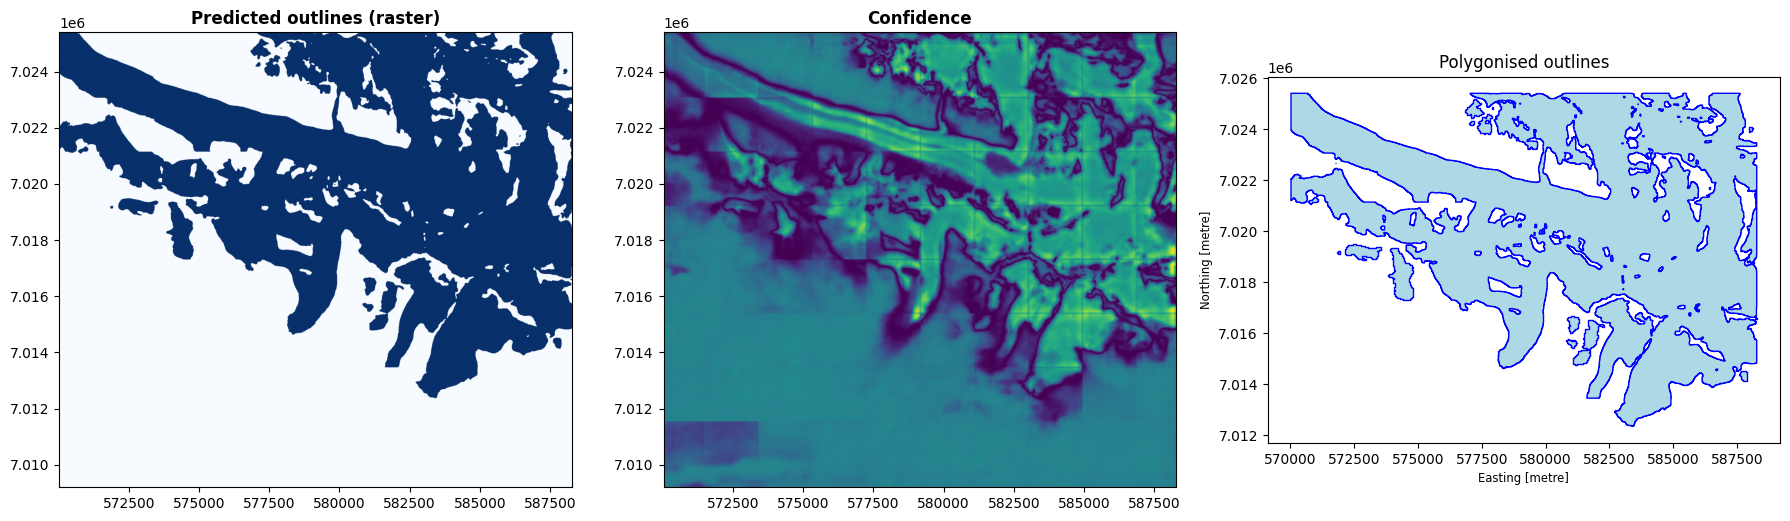

In [16]:
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import show

gdf = gpd.read_file("gulkana_output/glacier.shp")
print("Polygons:", len(gdf), "| CRS:", gdf.crs)
if len(gdf):
    print("Total glacier area: %.2f km²" % (gdf.geometry.area.sum() / 1e6))   # valid for projected (metre) CRS

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
with rasterio.open("gulkana_output/outlines.tif") as src:
    show(src, ax=ax[0], cmap="Blues", title="Predicted outlines (raster)")
with rasterio.open("gulkana_output/confidence.tif") as src:
    show(src, ax=ax[1], cmap="viridis", title="Confidence")
if len(gdf):
    gdf.plot(ax=ax[2], edgecolor="blue", facecolor="lightblue")
ax[2].set_title("Polygonised outlines")
plt.tight_layout()
plt.show()

## 8. Export (optional)

In [17]:
gdf.to_file("gulkana_output/glacier.geojson", driver="GeoJSON")

!zip -qr gulkana_output.zip gulkana_output/
from google.colab import files
files.download("gulkana_output.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>